# MTM field widths: GS2 $\phi$ and $A_\parallel$ equivalent Gaussian widths in $\theta_b$, width laws, predicted GFTM settings

Fusion_PhD-bhx7.17. The user (2026-11-17): use the extent-to-width transformation to get the width of each GS2 MTM's $\phi$ and
$A_\parallel$ separately, look at their distributions, fit width laws, and ask whether one set of GFTM settings can resolve both.

**The conversion is analytic, in the basis coordinate.** TGLF and GFTM expand each field in $\psi_n(x)\propto H_n(x)e^{-x^2/2}$ with
$x=\theta_b/\mathrm{WIDTH}$, where $\theta_b=2\pi l_\parallel/L_{\rm turn}$ is the arc length along the field line, not $\theta$.
pyrokinetics now maps $\theta\to\theta_b$ exactly from each sample's geometry: `FieldLine.compute_basis_angle` (pyro PR #617, the
cumulative form of `compute_length_per_turn`). In $\theta_b$, the 95 % extent of $|f|^2$ (pyro `Extent`) is
- $E=2.772\,W$ for an even field, $|\psi_0|^2\propto e^{-x^2}$;
- $E=3.953\,W$ for an odd field, $|\psi_1|^2\propto x^2e^{-x^2}$.

An MTM has tearing parity: $A_\parallel$ even, $\phi$ odd. So $W_{A_\parallel}=E^{\theta_b}_{A_\parallel}/2.772$ and $W_\phi=E^{\theta_b}_\phi/3.953$.
No runs are calibrated against. The notebook checks the map against GFTM itself (NBASIS-2 eigenfunctions are pure Hermite functions
in $\theta_b$) and against qp5.49's run-calibrated KBM widths.

**Populations.** GS2 `pyro_cube_avg` of NSTX_MTM n1000 (fit) and n300 (out of sample), as the law2 refit (`mtm_extent_law_refit`):
label MTM ($T>0.15$, $\omega<0$), $\gamma>0$, `growth_rate_tolerance` $<0.01$. A field whose $|f|^2$ has more than 1 % beyond
$0.9\max|\theta|$ touches the box: its extent, and so its width, is a lower bound (right-censored).

In [1]:
import os
from multiprocessing import get_context
from pathlib import Path
import time
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.ticker import NullLocator, StrMethodFormatter
from scipy import optimize, stats
from scipy.stats import chi2, norm
from pyrokinetics import Pyro, PyroHypercube
from pyrokinetics.diagnostics.extent import Extent
from pyrokinetics.diagnostics.field_line import FieldLine
from general_analysis import mode_classification as mc

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
plt.rcParams["lines.marker"] = ""     # the style marks every line; reference lines (axvline/axhline) must not carry dots
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
data_root = Path(os.path.expandvars(os.environ["GK_DATA_ROOT"]))     # the WORK tree
plots_dir = ROOT / "Plots" / "mtm_field_widths"
plots_dir.mkdir(parents=True, exist_ok=True)
n_cpu = int(os.environ.get("SLURM_CPUS_PER_TASK", 4))

draws = {"n1000": "beta_q_shat_ky_n1000", "n300": "beta_q_shat_ky_n300"}
arms = {"m11_new": "m11_new", "law2 rule": "extent_rule_tf035_law2", "law2 maxbasis": "extent_maxbasis_law2_s100", "fw174": "gftm_fw174"}
m11_width = 5.89285              # registry gftm_m11_new: FIND_WIDTH F, WIDTH 5.89285 (its cube does not record the width)
fields = ["phi", "apar"]
field_label = {"phi": r"$\phi$", "apar": r"$A_\parallel$"}
mtm_parity = {"phi": "odd", "apar": "even"}
kbm_parity = {"phi": "even", "apar": "odd"}
tolerance_gate, edge_gate = 1e-2, 1e-2
target_error = 0.03              # qp5.49: the extent-convergence criterion behaves like a Gaussian at 3 % relative L2 error
nbasis_cap, nxgrid_cap, nxgrid_floor = 59, 65, 14
kbm_cases = ["SPR-045", "M1", "R4", "R3"]
check_widths = [0.2, 0.4, 0.8, 1.6]
calibration_widths = [0.2, 0.2297, 0.2639, 0.3031, 0.3482, 0.4, 0.4595, 0.5279, 0.6063, 0.6965, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5,
                      1.6, 1.9218, 2.3083, 2.7726, 3.3302, 4.0]   # qp5.49's fixed-width GFTM NBASIS-2 ladder


def extent_95(power, coordinate):
    # pyro's 95 % Extent of |f|^2 over `coordinate` (theta or theta_b), finite points only
    keep = np.isfinite(power)
    return float(Extent._compute(xr.DataArray(power[keep][None], dims=("sample", "theta"), coords=dict(theta=coordinate[keep])), 0.95)[0][0])


def edge_fraction(power, theta):
    # share of |f|^2 beyond 0.9 of the run's own theta box (law2 refit's box-contact measure)
    keep = np.isfinite(power)
    power, theta = power[keep], theta[keep]
    return float(np.trapezoid(power * (abs(theta) > 0.9 * abs(theta).max()), theta) / np.trapezoid(power, theta))

## The analytic factors, and pyro's `Extent` on the models
qp5.43 (`basis_resolution_rule`) quoted $4.32\sigma$ for the odd model, measured with the `Extent` of that time. pyro's `Extent` is
now the central-95 % rule (2.5 % in each tail). On a fine grid it gives the $\chi^2_3$ quantile, $3.953$, for $x\,e^{-x^2/2}$; 4.32 is
not reproduced and is superseded.

In [2]:
analytic_factor = {"even": 2 * norm.ppf(0.975) / np.sqrt(2), "odd": 2 * np.sqrt(chi2.ppf(0.95, 3) / 2)}
x_fine = np.linspace(-12, 12, 200001)
model = {"even": lambda x: np.exp(-x ** 2 / 2), "odd": lambda x: x * np.exp(-x ** 2 / 2)}
for parity in model:
    measured = extent_95(model[parity](x_fine) ** 2, x_fine)
    assert abs(measured - analytic_factor[parity]) < 1e-3, (parity, measured)
    print(f"{parity}: pyro Extent {measured:.4f}, analytic {analytic_factor[parity]:.4f}")
assert abs(extent_95(model["odd"](x_fine) ** 2, x_fine) - 4.32) > 0.3

even: pyro Extent 2.7718, analytic 2.7718
odd: pyro Extent 3.9534, analytic 3.9534


## GS2 MTMs: label, map to $\theta_b$, extent and width per field
Per sample, one `FieldLine` on the sample's own Pyro (its geometry, the cube's $A_\parallel$ attached) gives the tearing parameter $T$
and the map $\theta\to\theta_b$. The label is GA's `classify_T_omega`. Each field's extent is pyro's 95 % `Extent` of $|f|^2$ in
$\theta_b$ (and in $\theta$, for reference); $\phi$ and $A_\parallel$ even fractions (pyro `compute_linear_parity`) check the parity
assumption.

In [5]:
def load_gs2(draw):
    cube_dir = data_root / "GS2/Runs/LATIN_HYPERCUBE/NSTX_MTM" / draws[draw] / "pyro_cube_avg"
    scan = PyroHypercube(pyro=Pyro(gk_file=cube_dir / "pyroscan_base.input", gk_code="GS2"), pyroscan_json=cube_dir / "pyroscan.json",
                         base_directory=cube_dir.parent, file_name="gs2.in")
    scan.load_gk_output(netcdf_file=cube_dir / "cube.nc")
    return scan


projection_widths = np.geomspace(0.5, 32, 19)
n_project = 160


def hermite_functions(x, n=n_project):
    # orthonormal psi_n(x) = H_n(x) exp(-x^2/2) / sqrt(2^n n! sqrt(pi)), n = 0 .. n-1, by the stable recurrence (tglf_hermite.f90's)
    psi = np.zeros((n, len(x)))
    psi[0] = np.pi ** -0.25 * np.exp(-x ** 2 / 2)
    psi[1] = np.sqrt(2) * x * psi[0]
    for k in range(2, n):
        psi[k] = np.sqrt(2 / k) * x * psi[k - 1] - np.sqrt((k - 1) / k) * psi[k - 2]
    return psi


x_check = np.linspace(-40, 40, 40001)
gram = hermite_functions(x_check) @ hermite_functions(x_check).T * (x_check[1] - x_check[0])
assert np.allclose(gram, np.eye(n_project), atol=1e-8)                              # orthonormal to n = 159


def gs2_sample(args):
    draw, i = args
    scan = gs2_scans[draw]
    output = scan.gk_output.data.isel(sample=i)
    finite_theta = output.apar.pint.dequantify().dropna("theta").sortby("theta").theta     # GS2 grids are NaN-padded to the union
    fields_theta = {field: output[field].pint.dequantify().sel(theta=finite_theta) for field in fields}
    field_line = FieldLine(scan.sample_pyro(i, gk_output=xr.Dataset(fields_theta)))
    theta = fields_theta["apar"].theta.values
    basis_angle = field_line.compute_basis_angle(theta)
    row = dict(draw=draw, sample=str(output.sample_name.values), ky=float(output.ky), shat=float(output.shat), q=float(output.q),
               beta=float(output.beta), gamma=float(output.growth_rate.pint.dequantify()),
               omega=mc.ION_DIRECTION * float(output.mode_frequency.pint.dequantify()),
               tolerance=float(output.growth_rate_tolerance.pint.dequantify()),
               T=float(field_line.compute_linear_tearing_parameter().squeeze()),
               phi_even=float(field_line.compute_linear_parity("phi").squeeze()), apar_even=float(field_line.compute_linear_parity("apar").squeeze()),
               stretch=float(np.gradient(basis_angle, theta)[np.argmin(abs(theta))]))
    for field in fields:
        power = np.abs(fields_theta[field].values) ** 2
        row[f"{field}_extent_theta"] = extent_95(power, theta)
        row[f"{field}_extent"] = extent_95(power, basis_angle)
        row[f"{field}_edge"] = edge_fraction(power, theta)
        row[f"{field}_width"] = row[f"{field}_extent"] / analytic_factor[mtm_parity[field]]
        weight = power * np.gradient(basis_angle)
        row[f"{field}_tail_fraction"] = float(weight[abs(basis_angle) > np.pi].sum() / weight.sum())   # |f|^2 beyond the first poloidal turn
        # projection of the complex field onto the code's basis psi_n(theta_b / WIDTH) / sqrt(WIDTH), as qp5.43: relative L2 error after N functions
        values, step = fields_theta[field].values.ravel(), np.gradient(basis_angle)
        for j, width in enumerate(projection_widths):
            coefficients = (hermite_functions(basis_angle / width) / np.sqrt(width)) @ (values * step)
            error = np.sqrt(np.maximum(1 - np.cumsum(np.abs(coefficients) ** 2) / (np.abs(values) ** 2 * step).sum(), 0))
            row[f"{field}_projected_needed_{j}"] = int(np.argmax(error <= target_error)) + 1 if (error <= target_error).any() else np.inf
            for nbasis in (24, nbasis_cap):
                row[f"{field}_projected_error_{nbasis}_{j}"] = float(error[nbasis - 1])
    return row


gs2_scans = {draw: load_gs2(draw) for draw in draws}
with get_context("fork").Pool(n_cpu) as pool:
    gs2 = pd.DataFrame(pool.map(gs2_sample, [(draw, i) for draw in draws for i in range(gs2_scans[draw].gk_output.data.sizes["sample"])], chunksize=8))
gs2["label"] = mc.classify_T_omega(gs2)
check = gs2[(gs2.draw == "n1000") & (gs2["sample"] == "iteration_33")].iloc[0]
assert round(check.ky, 5) == 0.58085 and round(check.shat, 5) == 1.32921        # Fusion_PhD-jmw0 guard: cube coordinates
mtm = gs2[(gs2.label == "MTM") & (gs2.gamma > 0) & (gs2.tolerance < tolerance_gate)].copy()
for field in fields:
    mtm[f"{field}_censored"] = mtm[f"{field}_edge"] >= edge_gate
mtm["ratio"] = mtm.phi_width / mtm.apar_width                                     # s^2 = W_phi / W_A_par
mtm["ratio_censored"] = mtm.phi_censored | mtm.apar_censored
counts = gs2.groupby("draw").agg(loaded=("sample", "size"), MTM=("label", lambda label: (label == "MTM").sum())).join(
    mtm.groupby("draw").agg(MTM_unstable_converged=("sample", "size"), phi_censored=("phi_censored", "sum"), apar_censored=("apar_censored", "sum"),
                            phi_even_median=("phi_even", "median"), apar_even_median=("apar_even", "median"),
                            phi_odd_share=("phi_even", lambda even: (even < 0.5).mean()), apar_even_share=("apar_even", lambda even: (even > 0.5).mean()),
                            stretch_median=("stretch", "median"), apar_tail_median=("apar_tail_fraction", "median"),
                            phi_tail_median=("phi_tail_fraction", "median")))
print(counts.round(3).to_string())

       loaded  MTM  MTM_unstable_converged  phi_censored  apar_censored  phi_even_median  apar_even_median  phi_odd_share  apar_even_share  stretch_median  apar_tail_median  phi_tail_median
draw                                                                                                                                                                                         
n1000    1000  757                     683            58             35              0.0               1.0            1.0              1.0           1.047             0.112            0.599
n300      300  226                     202            14              9              0.0               1.0            1.0              1.0           1.047             0.130            0.616


### What sets $W_{A_\parallel}$: one peak at $\theta_b=0$, or a train of peaks at $\theta_b=2\pi p$
$W_{A_\parallel}$ clusters at discrete values (the width-law figure below shows them as horizontal bands). The share of $|A_\parallel|^2$
beyond the first poloidal turn ($|\theta_b|>\pi$) separates the two shapes; below, $W_{A_\parallel}$ against that share, and one
eigenfunction from each band (median-$\gamma$ MTM of the band, n1000), $|f|^2$ normalised to its peak, against $\theta_b/\pi$, with the
Gaussian (dashed) that has the same extent.

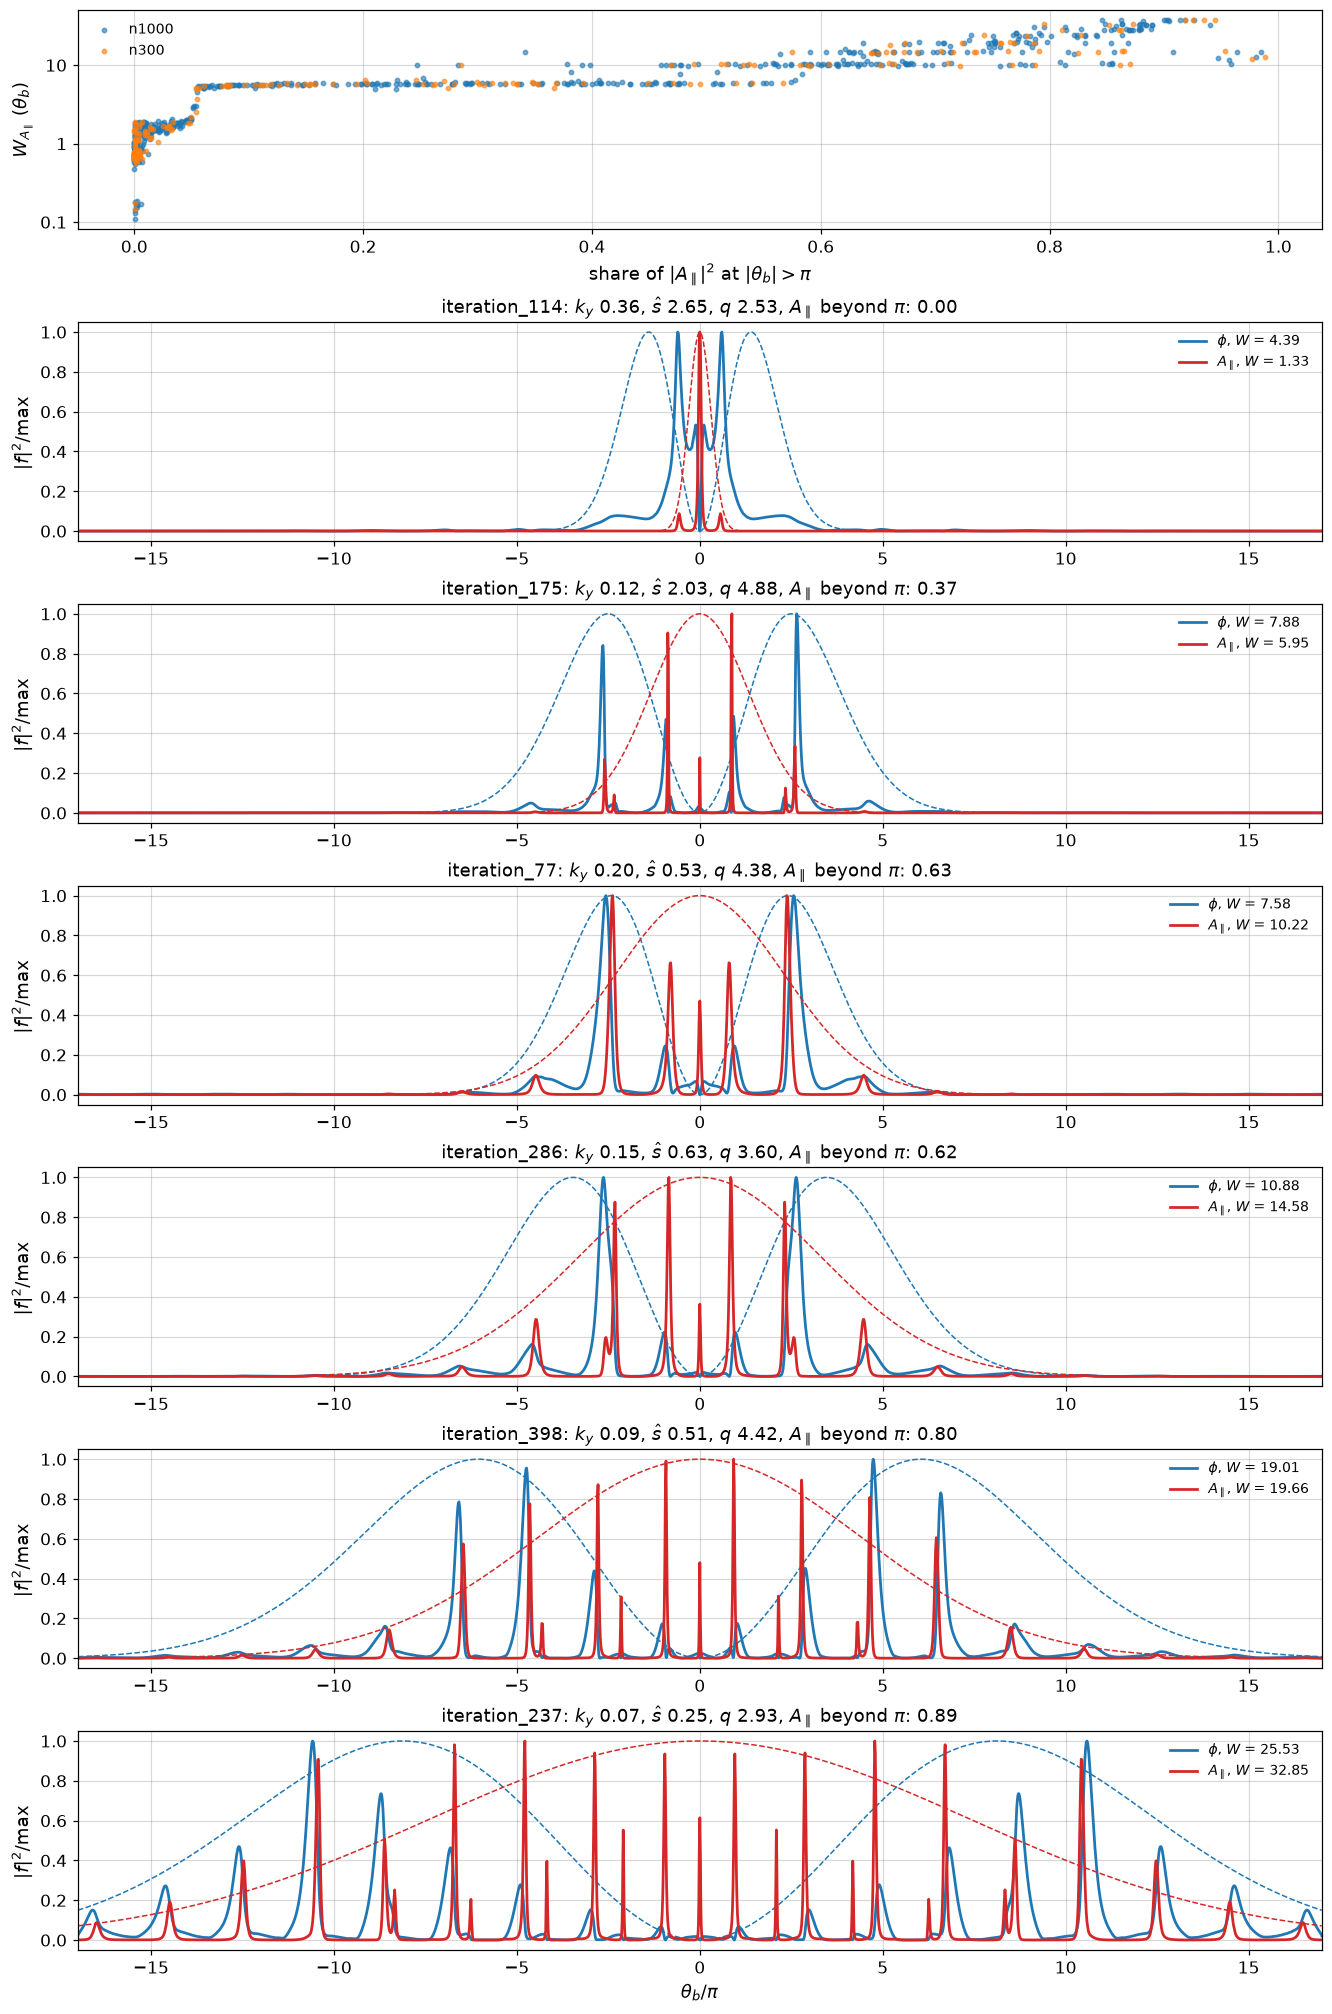

In [6]:
band_edges = [0, 3, 8, 12.5, 17.5, 25, np.inf]
mtm["apar_band"] = pd.cut(mtm.apar_width, band_edges)
print(mtm.groupby("apar_band", observed=True).agg(n=("sample", "size"), apar_width_median=("apar_width", "median"),
                                                 apar_tail_median=("apar_tail_fraction", "median"), phi_width_median=("phi_width", "median"),
                                                 shat_median=("shat", "median"), q_median=("q", "median"), ky_median=("ky", "median")).round(3).to_string())
examples = [rows.iloc[(rows.gamma - rows.gamma.median()).abs().argmin()] for _, rows in mtm[mtm.draw == "n1000"].groupby("apar_band", observed=True)
            if len(rows) >= 5]
fig, axes = plt.subplots(1 + len(examples), 1, figsize=(12, 2.6 * (1 + len(examples))), constrained_layout=True)
for draw, colour in zip(draws, ("C0", "C1")):
    rows = mtm[mtm.draw == draw]
    axes[0].scatter(rows.apar_tail_fraction, rows.apar_width, s=8, color=colour, alpha=0.6, label=draw)
axes[0].set(yscale="log", xlabel=r"share of $|A_\parallel|^2$ at $|\theta_b|>\pi$", ylabel=r"$W_{A_\parallel}$ ($\theta_b$)")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:g}")); axes[0].yaxis.set_minor_locator(NullLocator()); axes[0].legend(fontsize=9)
for ax, example in zip(axes[1:], examples):
    scan = gs2_scans["n1000"]
    output = scan.gk_output.data.set_index(sample="sample_name").sel(sample=example["sample"])
    finite_theta = output.apar.pint.dequantify().dropna("theta").sortby("theta").theta
    basis_angle = FieldLine(scan.sample_pyro(example["sample"], gk_output=xr.Dataset())).compute_basis_angle(finite_theta.values)
    for field, colour in zip(fields, ("C0", "C3")):
        power = np.abs(output[field].pint.dequantify().sel(theta=finite_theta).values) ** 2
        ax.plot(basis_angle / np.pi, power / power.max(), color=colour, marker="", label=f"{field_label[field]}, $W$ = {example[f'{field}_width']:.2f}")
        width = example[f"{field}_width"]
        ax.plot(basis_angle / np.pi, np.abs(model[mtm_parity[field]](basis_angle / width)) ** 2 / np.abs(model[mtm_parity[field]](basis_angle / width)).max() ** 2,
                color=colour, ls="--", lw=1, marker="")
    ax.set(xlim=(-17, 17), ylabel=r"$|f|^2/\max$", title=f"{example['sample']}: $k_y$ {example.ky:.2f}, $\\hat s$ {example.shat:.2f}, $q$ {example.q:.2f}, "
           f"$A_\\parallel$ beyond $\\pi$: {example.apar_tail_fraction:.2f}")
    ax.legend(fontsize=9, loc="upper right")
axes[-1].set_xlabel(r"$\theta_b/\pi$")

plt.show()

## Retrospective: does the width mismatch predict failure in the existing arms?
No runs. Arms on both draws: `m11_new` (WIDTH 5.893, NBASIS 24), `law2 rule` (`extent_rule_tf035_law2`, per-case WIDTH, NBASIS 8–59),
`law2 maxbasis` (`extent_maxbasis_law2_s100`, WIDTH $=1.6675K$, NBASIS 59), `fw174` (WIDTH 1.74, NBASIS 12). All FIND_WIDTH F.
Per MTM (paired: every arm built the case): GFTM's dominant mode (argmax $\gamma$); **detection** = $\gamma>0$, $\omega<0$, $T>0.15$
($T$ from pyro `FieldLine` on the GFTM $A_\parallel$); $|\log_{10}(\gamma_{\rm GFTM}/\gamma_{\rm GS2})|$ with misses ($\gamma\le0$) $+\infty$;
extent ratio $E_{\rm GFTM}/E_{\rm GS2}$ per field, both in $\theta$ (like-for-like: GFTM's eigenfunction is written on the Miller angle).
Plotted against $s_f=W_f/{\rm WIDTH}_{\rm used}$, in equal-width bins of $\log s_f$ (bins with fewer than 10 cases dropped).

draw                                   n1000                                      n300                                 
arm                                    fw174 law2 maxbasis law2 rule  m11_new    fw174 law2 maxbasis law2 rule  m11_new
n                                    672.000       672.000   672.000  672.000  199.000       199.000   199.000  199.000
detected                               0.499         0.826     0.787    0.726    0.467         0.879     0.759    0.719
medlog                                 0.478         0.341     0.380    0.272    0.410         0.374     0.385    0.259
s_phi_median                           4.485         5.815     2.908    1.324    4.616         5.610     2.919    1.363
s_apar_median                          3.202         3.585     1.874    0.945    3.232         3.783     1.924    0.954
phi_extent_ratio_median                0.370         0.671     0.613    0.878    0.337         0.681     0.640    0.881
apar_extent_ratio_median               0

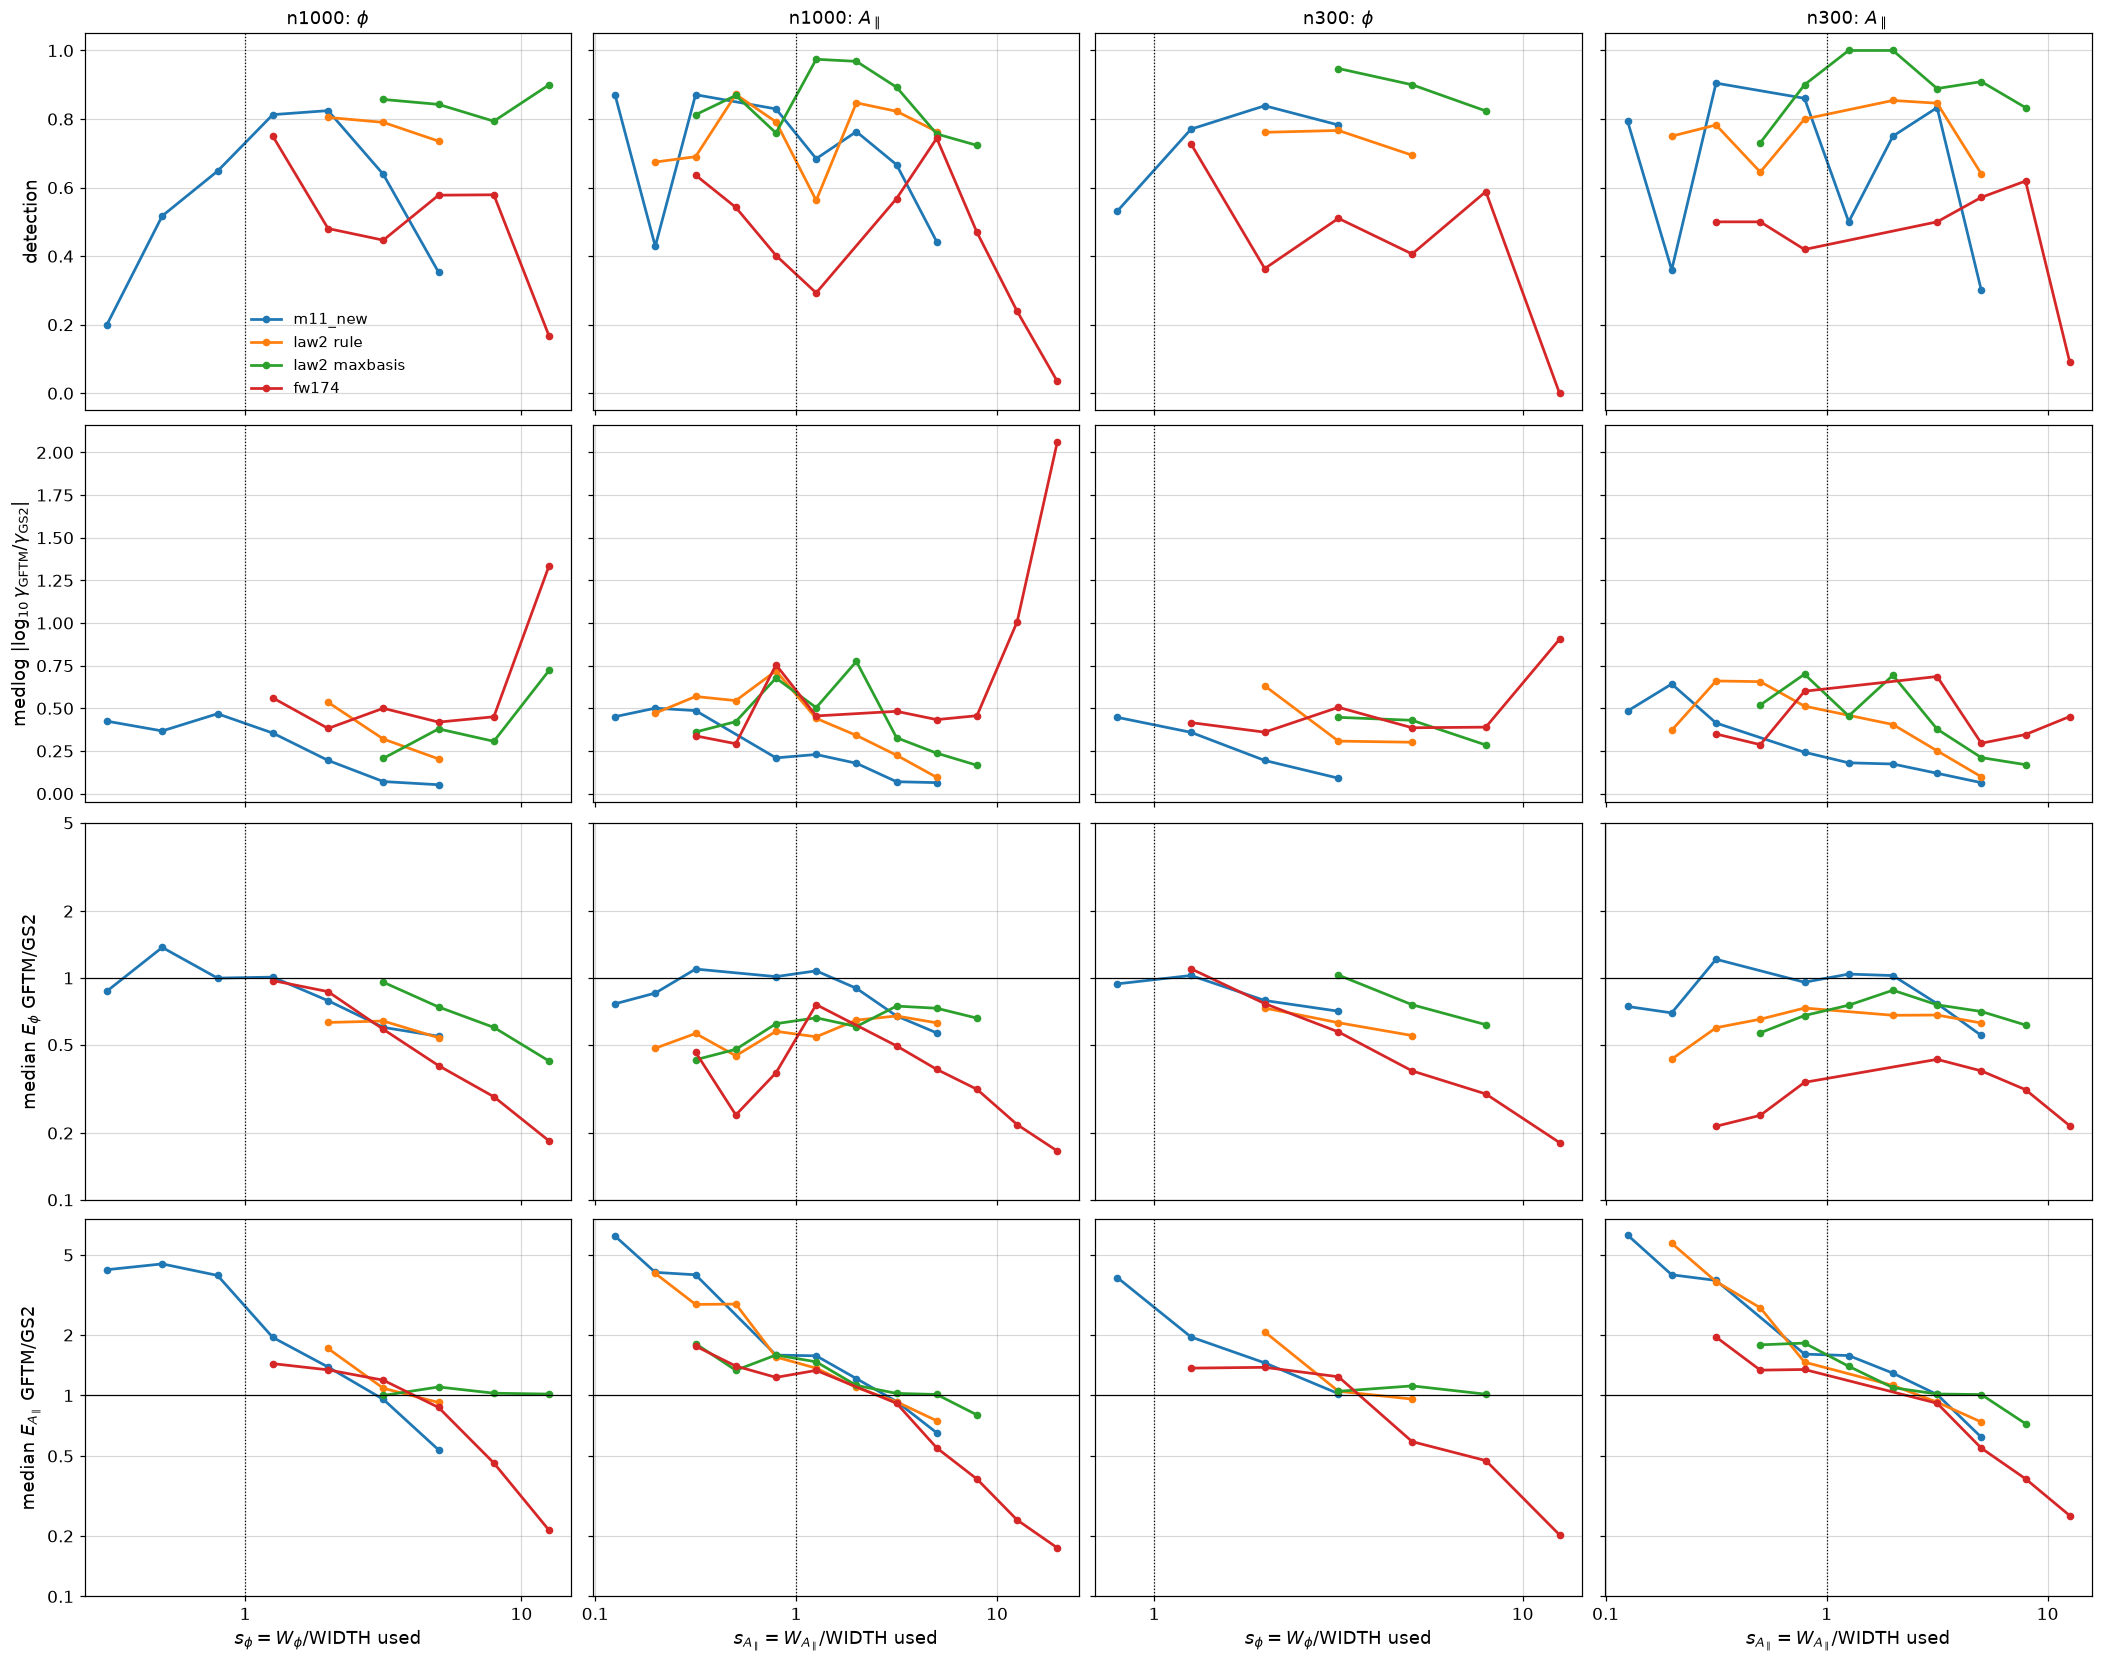

In [12]:
def load_arm(args):
    draw, arm = args
    leaf = data_root / "GFTM/Runs/LATIN_HYPERCUBE/NSTX_MTM" / draws[draw] / arms[arm]
    cube_dir = leaf / "pyro_cube" if (leaf / "pyro_cube").is_dir() else leaf
    scan = PyroHypercube(pyro=Pyro(gk_file=cube_dir / "pyroscan_base.input", gk_code="GFTM"), pyroscan_json=cube_dir / "pyroscan.json",
                         base_directory=leaf, file_name="input.gftm")
    scan.load_gk_output(netcdf_file=cube_dir / ("cube.nc" if (cube_dir / "cube.nc").exists() else "pyroscan.nc"))
    output = scan.gk_output.data
    wanted = set(mtm[mtm.draw == draw]["sample"])
    width_used = (output.WIDTH.values if "WIDTH" in output.coords else output.width_used.values if "width_used" in output.coords
                  else np.full(output.sizes["sample"], m11_width))
    gs2_extent = mtm[mtm.draw == draw].set_index("sample")
    rows = []
    for i, name in enumerate(output.sample_name.values):
        if str(name) not in wanted:
            continue
        sample_output = output.isel(sample=i)
        gamma = sample_output.growth_rate.pint.dequantify().values
        dominant = int(np.where(np.isfinite(gamma), gamma, -np.inf).argmax())
        eigenfunctions = sample_output.eigenfunctions.isel(mode=dominant).pint.dequantify().squeeze()
        apar = eigenfunctions.sel(field="apar").dropna("theta").sortby("theta")
        tearing = (FieldLine(scan.sample_pyro(i, gk_output=xr.Dataset({"apar": apar}))).compute_linear_tearing_parameter()
                   if apar.size and np.abs(apar).max() > 0 else np.nan)
        row = dict(draw=draw, arm=arm, sample=str(name), width_used=float(width_used[i]), gamma=float(gamma[dominant]),
                   omega=mc.ION_DIRECTION * float(sample_output.mode_frequency.pint.dequantify().values[dominant]), T=float(np.squeeze(tearing)))
        for field in fields:
            values = eigenfunctions.sel(field=field).dropna("theta").sortby("theta")
            row[f"{field}_extent_ratio"] = (extent_95(np.abs(values.values) ** 2, values.theta.values) / gs2_extent.loc[str(name), f"{field}_extent_theta"]
                                            if np.isfinite(row["gamma"]) and values.size and np.abs(values.values).max() > 0 else np.nan)
        rows.append(row)
    return pd.DataFrame(rows)


with get_context("fork").Pool(n_cpu) as pool:
    retro = pd.concat(pool.map(load_arm, [(draw, arm) for draw in draws for arm in arms]), ignore_index=True)
retro = retro.merge(mtm[["draw", "sample", "gamma", "phi_width", "apar_width", "phi_censored", "apar_censored"]].rename(columns=dict(gamma="gamma_gs2")),
                    on=["draw", "sample"], validate="many_to_one")
built = retro.groupby(["draw", "sample"]).arm.nunique() == len(arms)
retro = retro.join(built.rename("paired"), on=["draw", "sample"])
retro = retro[retro.paired].copy()
retro["detected"] = (retro.gamma > 0) & (retro.omega < 0) & (retro["T"] > mc.T_TEAR)
retro["log_error"] = np.where(retro.gamma > 0, np.abs(np.log10(retro.gamma.clip(lower=1e-300) / retro.gamma_gs2)), np.inf)
for field in fields:
    retro[f"s_{field}"] = retro[f"{field}_width"] / retro.width_used
retro_summary = retro.groupby(["draw", "arm"]).agg(n=("sample", "size"), detected=("detected", "mean"), medlog=("log_error", "median"),
                                                   s_phi_median=("s_phi", "median"), s_apar_median=("s_apar", "median"),
                                                   phi_extent_ratio_median=("phi_extent_ratio", "median"), apar_extent_ratio_median=("apar_extent_ratio", "median"))
s_bins = np.geomspace(0.01, 100, 21)
for field in fields:
    retro[f"s_{field}_bin"] = pd.cut(retro[f"s_{field}"], s_bins)
    for (draw, arm), rows in retro.groupby(["draw", "arm"]):
        within = rows[(rows[f"s_{field}"] >= 1 / 2) & (rows[f"s_{field}"] <= 2)]
        retro_summary.loc[(draw, arm), f"detected_s_{field}_within_2"] = within.detected.mean()
        retro_summary.loc[(draw, arm), f"detected_s_{field}_outside_2"] = rows.drop(within.index).detected.mean()
        retro_summary.loc[(draw, arm), f"spearman_detected_vs_abs_log_s_{field}"] = stats.spearmanr(abs(np.log(rows[f"s_{field}"])), rows.detected)[0]
retro_summary.to_csv(plots_dir / "retrospective_summary.csv")
print(retro_summary.round(3).T.to_string())

metrics = {"detected": ("detection", lambda values: values.mean()), "log_error": (r"medlog $|\log_{10}\gamma_{\rm GFTM}/\gamma_{\rm GS2}|$", lambda values: values.median()),
           "phi_extent_ratio": (r"median $E_\phi$ GFTM/GS2", lambda values: values.median()),
           "apar_extent_ratio": (r"median $E_{A_\parallel}$ GFTM/GS2", lambda values: values.median())}
fig, axes = plt.subplots(len(metrics), 4, figsize=(19, 15), sharex="col", sharey="row", constrained_layout=True)
for column, (draw, field) in enumerate([(draw, field) for draw in draws for field in fields]):
    for arm_index, arm in enumerate(arms):
        rows = retro[(retro.draw == draw) & (retro.arm == arm)]
        grouped = rows.groupby(f"s_{field}_bin", observed=True)
        enough = grouped.size() >= 10
        centres = np.array([np.sqrt(interval.left * interval.right) for interval in grouped.size().index])[enough.values]
        for row, (metric, (label, reduce)) in enumerate(metrics.items()):
            values = grouped[metric].apply(reduce)[enough.values]
            axes[row, column].plot(centres, values, "-o", ms=4, color=f"C{arm_index}", label=arm)
            axes[row, 0].set_ylabel(label)
    axes[0, column].set_title(f"{draw}: {field_label[field]}")
    axes[-1, column].set_xlabel({"phi": r"$s_\phi=W_\phi/$WIDTH used", "apar": r"$s_{A_\parallel}=W_{A_\parallel}/$WIDTH used"}[field])
    for row in range(len(metrics)):
        ax = axes[row, column]
        ax.axvline(1, color="k", lw=0.8, ls=":")
        ax.set_xscale("log"); ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}")); ax.xaxis.set_minor_locator(NullLocator())
for row in (2, 3):
    axes[row, 0].set_yscale("log"); axes[row, 0].yaxis.set_major_formatter(StrMethodFormatter("{x:g}")); axes[row, 0].yaxis.set_minor_locator(NullLocator()); axes[row, 0].set_yticks([0.1, 0.2, 0.5, 1, 2, 5])
    for column in range(4):
        axes[row, column].axhline(1, color="k", lw=0.8)
axes[0, 0].legend(fontsize=10)
fig.savefig(plots_dir / "gftm_mtm_error_and_capture_vs_width_ratio_per_settings.png", dpi=150); fig.savefig(plots_dir / "gftm_mtm_error_and_capture_vs_width_ratio_per_settings.pdf")
plt.show()

Low-level view behind it: every paired MTM per arm, $s_{A_\parallel}$ against $s_\phi$, detected (filled) and not detected (open red).

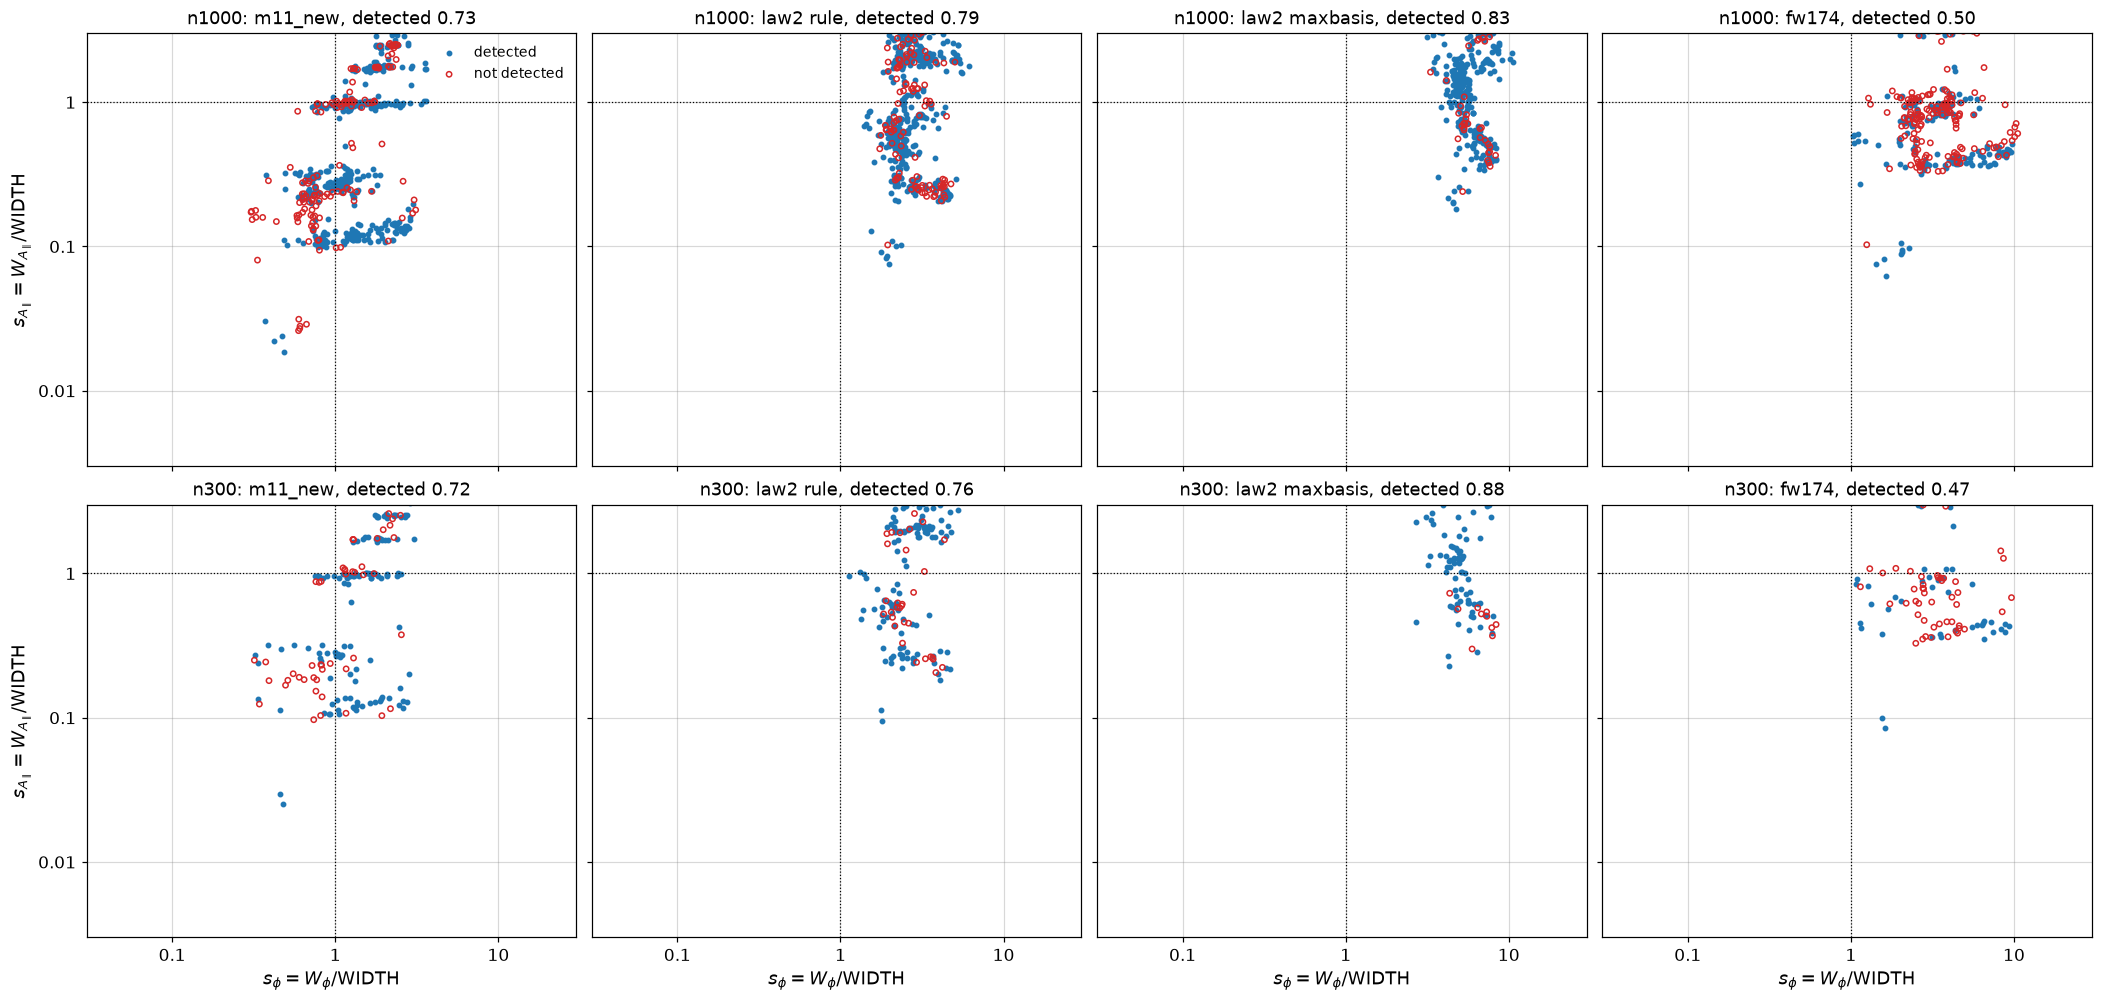

In [13]:
fig, axes = plt.subplots(2, len(arms), figsize=(19, 9), sharex=True, sharey=True, constrained_layout=True)
for row, draw in enumerate(draws):
    for column, arm in enumerate(arms):
        ax = axes[row, column]
        rows = retro[(retro.draw == draw) & (retro.arm == arm)]
        ax.scatter(rows.s_phi[rows.detected], rows.s_apar[rows.detected], s=8, c="C0", label="detected")
        ax.scatter(rows.s_phi[~rows.detected], rows.s_apar[~rows.detected], s=12, facecolors="none", edgecolors="C3", label="not detected")
        ax.axvline(1, color="k", lw=0.8, ls=":"); ax.axhline(1, color="k", lw=0.8, ls=":")
        ax.set(xscale="log", yscale="log", xlim=(0.03, 30), ylim=(0.003, 3), title=f"{draw}: {arm}, detected {rows.detected.mean():.2f}")
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_formatter(StrMethodFormatter("{x:g}")); axis.set_minor_locator(NullLocator())
    axes[row, 0].set_ylabel(r"$s_{A_\parallel}=W_{A_\parallel}/$WIDTH")
for ax in axes[-1]:
    ax.set_xlabel(r"$s_\phi=W_\phi/$WIDTH")
axes[0, 0].legend(fontsize=9)
fig.savefig(plots_dir / "gftm_mtm_detected_apar_width_ratio_vs_phi_width_ratio.png", dpi=150); fig.savefig(plots_dir / "gftm_mtm_detected_apar_width_ratio_vs_phi_width_ratio.pdf")
plt.show()